<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [scikit-bio](https://github.com/Query-farm/vgi-scikit-bio)

Bioinformatics functions for sequence analysis, alignment, microbial diversity, ordination and phylogenetic trees.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-scikit-bio/blob/main/notebooks/05_tree_scale_is_not_topology.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-scikit-bio/blob/main/notebooks/README.md)


## 05 · Tree scale is not topology

If every pairwise distance doubles, what should a tree comparison report? We construct trees with four worker algorithms, compare their baseline and rescaled outputs, and distinguish topology, branch-length distance and the worker's scale-insensitive cophenetic metric.

All four labels and six distances are **synthetic**. Units are arbitrary distance units, not years or substitutions per site. `LENGTH_SCALE` is a finite number from **1 to 3**, default **1.0**; the experiment uses **2.0**. This is a uniform change of numeric scale, not a simulated evolutionary process.

In [1]:
LENGTH_SCALE = 1.0  # multiply all distances; experiment: 2.0

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.29":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.29"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the kernel, then run all cells.")

from vgi_notebooks import check_runtime  # noqa: E402

check_runtime()

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme

if (
    type(LENGTH_SCALE) not in (int, float)
    or not np.isfinite(LENGTH_SCALE)
    or not 1 <= LENGTH_SCALE <= 3
):
    raise ValueError("LENGTH_SCALE must be a finite number from 1 to 3.")
theme()
session = connect(globals())
Path("artifacts").mkdir(exist_ok=True)
SOURCE = "Source: authored synthetic inputs · actual vgi-scikit-bio v0.3.0 worker · no biological inference"

### Connect to the released scientific worker

The short literal Git-tag launcher uses **v0.3.0** in a separate Python 3.13 process. Its release owns scientific and protocol dependencies; no source checkout or transitive overrides are needed. The notebook kernel uses the shared base package. First use downloads the worker and VGI; all analytical inputs below are synthetic and local. Shared connection setup creates an empty temporary SQL secret directory and disables persistent secrets.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'skbio' (TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-scikit-bio@v0.3.0 vgi-scikit-bio');

,Success


### Hold the six-pair pattern fixed while changing its units

The complete upper triangle is sufficient for this worker: it symmetrizes the matrix and fills a zero diagonal. Every one of the four labels is retained, and the six unordered pairs are unique. We materialize both matrices before constructing any trees.

Neighbor joining, greedy minimum evolution (GME), balanced minimum evolution (BME) and UPGMA answer different construction objectives. UPGMA produces an ultrametric rooted clustering; the other constructions do not impose a molecular clock. This small synthetic example cannot establish which method is appropriate for real data.

In [5]:
%%sql
CREATE TABLE distance_reference AS SELECT * FROM (VALUES
 ('a','b',5.0),('a','c',9.0),('a','d',9.0),
 ('b','c',10.0),('b','d',10.0),('c','d',8.0)
) AS t(id_1,id_2,distance);
CREATE TABLE distance_selected AS SELECT id_1,id_2,distance*{{LENGTH_SCALE}} AS distance FROM distance_reference;
SELECT r.id_1,r.id_2,r.distance AS reference_distance,s.distance AS selected_distance
FROM distance_reference r JOIN distance_selected s USING(id_1,id_2) ORDER BY id_1,id_2;

,id_1,id_2,reference_distance,selected_distance
0,a,b,5.0,5.0
1,a,c,9.0,9.0
2,a,d,9.0,9.0
3,b,c,10.0,10.0
4,b,d,10.0,10.0
5,c,d,8.0,8.0


In [6]:
%%sql
CREATE TABLE trees AS
SELECT 'reference' AS scenario,'NJ' AS method,newick FROM skbio.tree.neighbor_joining((SELECT * FROM distance_reference ORDER BY id_1,id_2))
UNION ALL SELECT 'selected','NJ',newick FROM skbio.tree.neighbor_joining((SELECT * FROM distance_selected ORDER BY id_1,id_2))
UNION ALL SELECT 'reference','UPGMA',newick FROM skbio.tree.upgma((SELECT * FROM distance_reference ORDER BY id_1,id_2))
UNION ALL SELECT 'selected','UPGMA',newick FROM skbio.tree.upgma((SELECT * FROM distance_selected ORDER BY id_1,id_2))
UNION ALL SELECT 'reference','GME',newick FROM skbio.tree.gme((SELECT * FROM distance_reference ORDER BY id_1,id_2))
UNION ALL SELECT 'selected','GME',newick FROM skbio.tree.gme((SELECT * FROM distance_selected ORDER BY id_1,id_2))
UNION ALL SELECT 'reference','BME',newick FROM skbio.tree.bme((SELECT * FROM distance_reference ORDER BY id_1,id_2))
UNION ALL SELECT 'selected','BME',newick FROM skbio.tree.bme((SELECT * FROM distance_selected ORDER BY id_1,id_2));
SELECT * FROM trees ORDER BY method,scenario;

,scenario,method,newick
0,reference,BME,"(b:3.0,(c:4.0,d:4.0):3.0,a:2.0);"
1,selected,BME,"(b:3.0,(c:4.0,d:4.0):3.0,a:2.0);"
2,reference,GME,"(b:3.0,(c:4.0,d:4.0):3.0,a:2.0);"
3,selected,GME,"(b:3.0,(c:4.0,d:4.0):3.0,a:2.0);"
4,reference,NJ,"((a:2.0,b:3.0):3.0,d:4.0,c:4.0);"
5,selected,NJ,"((a:2.0,b:3.0):3.0,d:4.0,c:4.0);"
6,reference,UPGMA,"((a:2.5,b:2.5):2.25,(c:4.0,d:4.0):0.75);"
7,selected,UPGMA,"((a:2.5,b:2.5):2.25,(c:4.0,d:4.0):0.75);"


### Measure the returned trees before comparing them

`tip_count` checks that each algorithm kept all four labels. `total_branch_length` sums the stored edges; `tree_height` is the maximum distance from the serialized root to a tip. Height is therefore root-dependent, especially for an unrooted construction serialized with a chosen root. Do not read it as an evolutionary age or compare rooting conventions as if they were interchangeable.

A uniform positive scaling should multiply both length summaries within each method. Agreement on this property does not mean the methods produce identical branch lengths.

In [7]:
%%sql
CREATE TABLE measurements AS SELECT scenario,method,newick,
 skbio.tree.tip_count(newick) AS tips,
 skbio.tree.total_branch_length(newick) AS total_length,
 skbio.tree.tree_height(newick) AS root_to_tip_height
FROM trees;
CREATE TABLE comparison AS SELECT r.method,r.tips AS reference_tips,s.tips AS selected_tips,
 r.total_length AS reference_length,s.total_length AS selected_length,
 r.root_to_tip_height AS reference_height,s.root_to_tip_height AS selected_height,
 skbio.tree.robinson_foulds(r.newick,s.newick) AS rf_splits,
 skbio.tree.weighted_robinson_foulds(r.newick,s.newick) AS weighted_rf,
 skbio.tree.cophenetic_distance(r.newick,s.newick) AS cophenetic_unitcorr
FROM measurements r JOIN measurements s USING(method)
WHERE r.scenario='reference' AND s.scenario='selected';
SELECT * FROM comparison ORDER BY method;

,method,reference_tips,selected_tips,reference_length,selected_length,reference_height,selected_height,rf_splits,weighted_rf,cophenetic_unitcorr
0,BME,4,4,16.0,16.0,7.00,7.00,0.0,0.0,0.0
1,GME,4,4,16.0,16.0,7.00,7.00,0.0,0.0,0.0
2,NJ,4,4,16.0,16.0,6.00,6.00,0.0,0.0,0.0
3,UPGMA,4,4,16.0,16.0,4.75,4.75,0.0,0.0,0.0


In [8]:
%%sql metrics <<
SELECT * FROM comparison ORDER BY method;

,method,reference_tips,selected_tips,reference_length,selected_length,reference_height,selected_height,rf_splits,weighted_rf,cophenetic_unitcorr
0,BME,4,4,16.0,16.0,7.00,7.00,0.0,0.0,0.0
1,GME,4,4,16.0,16.0,7.00,7.00,0.0,0.0,0.0
2,NJ,4,4,16.0,16.0,6.00,6.00,0.0,0.0,0.0
3,UPGMA,4,4,16.0,16.0,4.75,4.75,0.0,0.0,0.0


All **4 methods** return four tips. With scale **1**, their total branch lengths and serialized-root heights scale by that factor. The method-specific reference lengths remain visible; we do not select a preferred biological model from this construction.

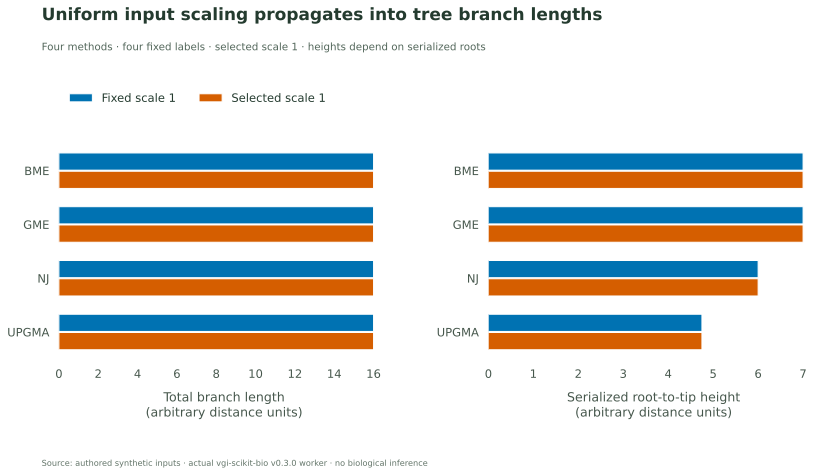

In [9]:
display(metrics)
prose(
    f"All **{len(metrics)} methods** return four tips. With scale **{LENGTH_SCALE:g}**, their total branch lengths and serialized-root heights scale by that factor. The method-specific reference lengths remain visible; we do not select a preferred biological model from this construction."
)
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
y = np.arange(len(metrics))
for ax, a, b, label in [
    (
        axes[0],
        metrics.reference_length,
        metrics.selected_length,
        "Total branch length\n(arbitrary distance units)",
    ),
    (
        axes[1],
        metrics.reference_height,
        metrics.selected_height,
        "Serialized root-to-tip height\n(arbitrary distance units)",
    ),
]:
    ax.barh(y - 0.17, a, height=0.32, color="#0072B2", label="Fixed scale 1")
    ax.barh(y + 0.17, b, height=0.32, color="#D55E00", label=f"Selected scale {LENGTH_SCALE:g}")
    ax.set_yticks(y, metrics.method)
    ax.invert_yaxis()
    ax.set_xlabel(label)
    ax.grid(axis="y", visible=False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.09, 0.82), ncol=2)
finish(
    fig,
    "Uniform input scaling propagates into tree branch lengths",
    f"Four methods · four fixed labels · selected scale {LENGTH_SCALE:g} · heights depend on serialized roots",
    SOURCE,
    name=f"tree-lengths-{LENGTH_SCALE:g}",
)

### Three distances deliberately ignore different information

Robinson–Foulds counts differing splits and ignores lengths. Weighted RF incorporates branch-length differences. The worker's `cophenetic_distance` calls scikit-bio's **unit correlation distance, (1−r)/2**, on pairwise tip-path lengths. It is **insensitive to a common positive scale**. A zero result therefore does not prove that absolute path lengths are identical.

This is narrower than the worker's broad catalog description “branch-length sensitive.” The [upstream metric definition](https://scikit.bio/docs/latest/generated/skbio.tree.TreeNode.compare_cophenet.html) and the actual controlled results establish the precise behavior. We compare identical, uniformly rescaled and topology-swapped rooted trees to make the distinction visible.

In [10]:
%%sql
CREATE TABLE controls AS SELECT * FROM (VALUES
 ('identical','((a:1,b:1):1,(c:1,d:1):1);'),
 ('uniform_scale','((a:{{LENGTH_SCALE}},b:{{LENGTH_SCALE}}):{{LENGTH_SCALE}},(c:{{LENGTH_SCALE}},d:{{LENGTH_SCALE}}):{{LENGTH_SCALE}});'),
 ('topology_swap','((a:1,c:1):1,(b:1,d:1):1);')
) AS t(control,newick);
CREATE TABLE control_metrics AS SELECT control,
 skbio.tree.tip_count(newick) AS tips,
 skbio.tree.total_branch_length(newick) AS total_length,
 skbio.tree.robinson_foulds('((a:1,b:1):1,(c:1,d:1):1);',newick) AS rf_splits,
 skbio.tree.weighted_robinson_foulds('((a:1,b:1):1,(c:1,d:1):1);',newick) AS weighted_rf,
 skbio.tree.cophenetic_distance('((a:1,b:1):1,(c:1,d:1):1);',newick) AS cophenetic_unitcorr
FROM controls;
SELECT * FROM control_metrics ORDER BY control;

,control,tips,total_length,rf_splits,weighted_rf,cophenetic_unitcorr
0,identical,4,6.0,0.0,0.0,0.00
1,topology_swap,4,6.0,4.0,4.0,0.75
2,uniform_scale,4,6.0,0.0,0.0,0.00


In [11]:
%%sql controls_frame <<
SELECT * FROM control_metrics ORDER BY control;

In [12]:
%%sql checks <<
SELECT 'six_unique_pairs' AS check_name,count(*)=6 AND count(DISTINCT(id_1,id_2))=6 AND bool_and(id_1<id_2 AND distance>0) AS passed FROM distance_reference
UNION ALL SELECT 'eight_trees_four_tips',count(*)=8 AND bool_and(tips=4) FROM measurements
UNION ALL SELECT 'length_scaling',bool_and(abs(selected_length-reference_length*{{LENGTH_SCALE}})<1e-8) FROM comparison
UNION ALL SELECT 'height_scaling',bool_and(abs(selected_height-reference_height*{{LENGTH_SCALE}})<1e-8) FROM comparison
UNION ALL SELECT 'same_method_same_topology',bool_and(abs(rf_splits)<1e-12) FROM comparison
UNION ALL SELECT 'cophenetic_ignores_uniform_scale',bool_and(abs(cophenetic_unitcorr)<1e-12) FROM comparison
UNION ALL SELECT 'controlled_identical_zero',rf_splits=0 AND weighted_rf=0 AND abs(cophenetic_unitcorr)<1e-12 FROM control_metrics WHERE control='identical'
UNION ALL SELECT 'controlled_scale_is_not_topology',rf_splits=0 AND abs(cophenetic_unitcorr)<1e-12 AND abs(total_length-6*{{LENGTH_SCALE}})<1e-12 FROM control_metrics WHERE control='uniform_scale'
UNION ALL SELECT 'weighted_distance_detects_nonunit_scale',(weighted_rf>0)=({{LENGTH_SCALE}}<>1) FROM control_metrics WHERE control='uniform_scale'
UNION ALL SELECT 'topology_control_detected',rf_splits>0 AND weighted_rf>0 AND cophenetic_unitcorr>0 FROM control_metrics WHERE control='topology_swap';

,check_name,passed
0,six_unique_pairs,True
1,eight_trees_four_tips,True
2,length_scaling,True
3,height_scaling,True
4,same_method_same_topology,True
5,cophenetic_ignores_uniform_scale,True
6,controlled_identical_zero,True
7,controlled_scale_is_not_topology,True
8,weighted_distance_detects_nonunit_scale,True
9,topology_control_detected,True


The controlled scale-1 tree has total length **6**, weighted RF **0**, split RF **0** and unit-correlation cophenetic distance **0.000000**. The topology-swap control is detected by all three comparisons. All **10 checks** pass.

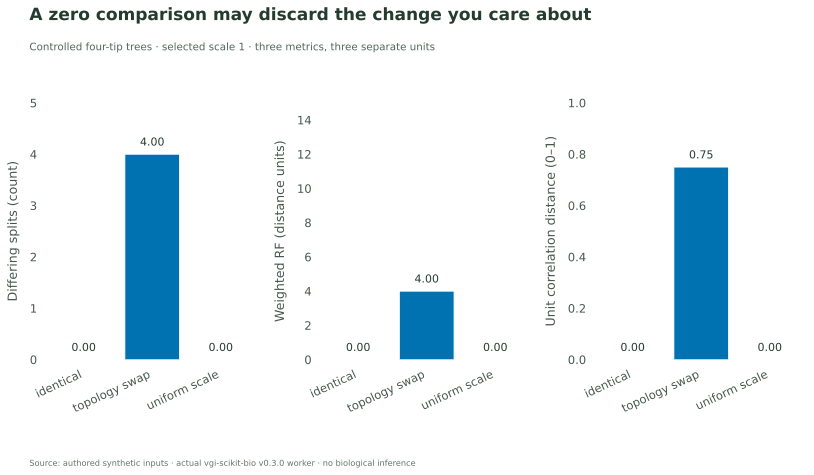

2604

In [13]:
display(checks)
assert checks.passed.all()
scale = controls_frame[controls_frame.control == "uniform_scale"].iloc[0]
prose(
    f"The controlled scale-{LENGTH_SCALE:g} tree has total length **{scale.total_length:g}**, weighted RF **{scale.weighted_rf:g}**, split RF **{scale.rf_splits:g}** and unit-correlation cophenetic distance **{scale.cophenetic_unitcorr:.6f}**. The topology-swap control is detected by all three comparisons. All **{len(checks)} checks** pass."
)
fig, axes = plt.subplots(1, 3, figsize=(12, 7))
labels = controls_frame.control.str.replace("_", " ")
for ax, col, label, limit in [
    (axes[0], "rf_splits", "Differing splits (count)", 5),
    (axes[1], "weighted_rf", "Weighted RF (distance units)", 15),
    (axes[2], "cophenetic_unitcorr", "Unit correlation distance (0–1)", 1),
]:
    bars = ax.bar(range(3), controls_frame[col], color=["#999999", "#0072B2", "#D55E00"])
    ax.bar_label(bars, fmt="%.2f", padding=6)
    ax.set_xticks(range(3), labels, rotation=25, ha="right")
    ax.set_ylim(0, limit)
    ax.set_ylabel(label)
    ax.grid(axis="x", visible=False)
finish(
    fig,
    "A zero comparison may discard the change you care about",
    f"Controlled four-tip trees · selected scale {LENGTH_SCALE:g} · three metrics, three separate units",
    SOURCE,
    name=f"tree-controls-{LENGTH_SCALE:g}",
)
Path("artifacts/analysis-05.json").write_text(
    json.dumps(
        {
            "scale": LENGTH_SCALE,
            "metrics": metrics.to_dict("records"),
            "controls": controls_frame.to_dict("records"),
            "checks": checks.to_dict("records"),
        },
        indent=2,
    )
)

### Experiment: double every input distance

Change `LENGTH_SCALE` from **1.0 to 2.0**. Every selected tree's total length and root-dependent height should double. Its topology and unit-correlation cophenetic comparison to the reference should remain unchanged, while weighted RF becomes positive. The fixed topology-swap control must not change.

Changing numeric scale does not introduce new evidence about relationships. None of these trees is a validated phylogeny, and zero topology or correlation distance is not a claim of identical absolute branch lengths.

In [14]:
session.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-scikit-bio](https://github.com/Query-farm/vgi-scikit-bio)
